In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [1]:
import pandas as pd
import re
from gensim.models.doc2vec import Doc2Vec, TaggedDocument
from gensim.utils import simple_preprocess
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np


# SimCSE ARABERT


In [ ]:
import re, random
import pandas as pd
from sentence_transformers import SentenceTransformer, InputExample, losses, models
from torch.utils.data import DataLoader

# Load the cleaned Hadith dataset
df = pd.read_csv('/kaggle/input/hadith-dataset/all_hadiths_clean.csv')

# Allow pandas to display full Matn text without truncation
pd.set_option('display.max_colwidth', None)

def extract_matn(text):
    # Ensure input is string and remove surrounding whitespace
    text = str(text).strip()

    # Extract quoted segments—if present, consider them the Matn
    quotes = re.findall(r'\"(.*?)\"', text)
    if quotes:
        return " ".join(q.strip() for q in quotes if q.strip())
    
    # Fallback triggers indicating where the Matn likely begins
    triggers = ["قال رسول الله", "قال النبي", "عن النبي", "عن رسول الله", "أن رسول الله"]
    for t in triggers:
        # If trigger appears, return everything after it
        if t in text:
            return text.split(t, 1)[-1].strip()

    # If no quotation or trigger is found, return full text as-is
    return text


In [ ]:
# Apply the Matn extraction function to each Arabic Hadith text
df["clean_text"] = df["text_ar"].apply(extract_matn)

# Remove rows missing Matn or chapter number, then reset indexing
df = df.dropna(subset=["clean_text", "chapter_no"]).reset_index(drop=True)

# Display total number of processed Hadith entries
print("Total hadith sentences:", len(df))

Total hadith sentences: 34441


In [ ]:
# Load AraBERTv2 as the transformer encoder with a maximum sequence length of 128 tokens
bert = models.Transformer("aubmindlab/bert-base-arabertv2", max_seq_length=128)

# Apply mean pooling to convert token-level embeddings into a single sentence embedding
pooling = models.Pooling(
    bert.get_word_embedding_dimension(),
    pooling_mode_mean_tokens=True
)

# Build the SentenceTransformer model by combining the AraBERT encoder with the pooling layer
model = SentenceTransformer(modules=[bert, pooling])

config.json:   0%|          | 0.00/384 [00:00<?, ?B/s]

/usr/local/lib/python3.11/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` 

model.safetensors:   0%|          | 0.00/543M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/611 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Chapter 77: 194
Chapter 98: 194
Chapter 67: 186
Chapter 81: 185
Chapter 34: 183
Chapter 63: 173
Chapter 8: 166
Chapter 60: 154
Chapter 61: 151
Chapter 23: 148
Chapter 59: 131
Chapter 62: 120
Chapter 4: 114
Chapter 24: 113
Chapter 30: 111
Chapter 80: 106


In [ ]:
# Display the unique source names available in the dataset
print(df["source"].unique())

[' Sahih Bukhari ' ' Sahih Muslim ' " Sunan Abi Da'ud "
 " Jami' al-Tirmidhi " " Sunan an-Nasa'i " ' Sunan Ibn Majah ']


In [ ]:
# Define the chapter IDs selected for training and evaluation
selected_chapters = [77, 98, 67, 81, 34, 63, 8, 60, 61, 23, 59, 62, 4, 24, 30, 80]

# Filter the dataset to include only Sahih Bukhari and the selected chapters
df_bukhari = df[
    (df["source"] == " Sahih Bukhari ") &
    (df["chapter_no"].isin(selected_chapters))
].reset_index(drop=True)

# Print total number of Hadiths used from the filtered subset
print("Total selected hadiths:", len(df_bukhari))

# Print count of Hadiths per chapter to verify dataset balance
print(df_bukhari.groupby("chapter_no").size())

Total selected hadiths: 2429
chapter_no
4     114
8     166
23    148
24    113
30    111
34    183
59    131
60    154
61    151
62    120
63    173
67    186
77    194
80    106
81    185
98    194
dtype: int64


# names of chapters

In [ ]:
# Get all unique sources (e.g., Sahih Bukhari, Sahih Muslim, etc.)
sources = df["source"].unique()

for src in sources:
    # Print header for the current source
    print(f"\n\n===== SOURCE: {src} =====")
    
    # Filter dataset to include only entries from this specific source
    df_src = df[df["source"] == src]

    # Count how many Hadiths exist in each chapter, sorted by descending frequency
    chapter_counts = (
        df_src["chapter_no"]
        .value_counts()
        .sort_values(ascending=False)
    )

    # Map each chapter number to its chapter name (remove duplicates first)
    chapter_names = (
        df_src[["chapter_no", "chapter"]]
        .drop_duplicates()
        .set_index("chapter_no")["chapter"]
    )

    # Display chapter number, chapter name, and count of Hadiths
    for chap_no, count in chapter_counts.items():
        chap_name = chapter_names.get(chap_no, "Unknown")
        print(f"Chapter {chap_no} — {chap_name}: {count}")



===== SOURCE:  Sahih Bukhari  =====
Chapter 65 — Prophetic Commentary on the Qur'an (Tafseer of the Prophet (pbuh)) - كتاب التفسير: 509
Chapter 64 — Military Expeditions led by the Prophet (pbuh) (Al-Maghaazi) - كتاب المغازى: 499
Chapter 56 — Fighting for the Cause of Allah (Jihaad) - كتاب الجهاد والسير: 294
Chapter 10 — Call to Prayers (Adhaan) - كتاب الأذان: 266
Chapter 78 — Good Manners and Form (Al-Adab) - كتاب الأدب: 256
Chapter 25 — Hajj (Pilgrimage) - كتاب الحج: 247
Chapter 77 — Dress - كتاب اللباس: 194
Chapter 98 — Oneness; Uniqueness of Allah (Tawheed) - كتاب التوحيد: 194
Chapter 67 — Wedlock; Marriage (Nikaah) - كتاب النكاح: 186
Chapter 81 — To make the Heart Tender (Ar-Riqaq) - كتاب الرقاق: 185
Chapter 34 — Sales and Trade - كتاب البيوع: 183
Chapter 63 — Merits of the Helpers in Madinah (Ansaar) - كتاب مناقب الأنصار: 173
Chapter 8 — Prayers (Salat) - كتاب الصلاة: 166
Chapter 60 — Prophets - كتاب أحاديث الأنبياء: 154
Chapter 61 — Virtues and Merits of the Prophet (pbuh) and

# make pairs

In [ ]:
examples = []

# Number of positive and negative pairs to generate per chapter
TARGET_PAIRS = 105  

for chap in selected_chapters:

    # Retrieve all Hadith Matn texts belonging to this chapter
    same = df_bukhari[df_bukhari["chapter_no"] == chap]["clean_text"].tolist()
    
    # ---------------------------------------------------------
    # Generate positive pairs: two Hadiths from the same chapter
    # ---------------------------------------------------------
    for _ in range(TARGET_PAIRS):
        a, b = random.sample(same, 2)  # Pick two distinct Hadiths
        examples.append(InputExample(texts=[a, b], label=1.0))  # Label 1 = semantically similar

    # ---------------------------------------------------------
    # Generate negative pairs: one Hadith from this chapter,
    # paired with another from a *different* chapter
    # ---------------------------------------------------------
    for _ in range(TARGET_PAIRS):
        a = random.choice(same)  # Anchor Hadith

        # Select a different chapter randomly
        other_chap = random.choice([c for c in selected_chapters if c != chap])

        # Sample one Hadith from the other chapter
        b = df_bukhari[df_bukhari["chapter_no"] == other_chap]["clean_text"].sample(1).values[0]

        examples.append(InputExample(texts=[a, b], label=0.0))  # Label 0 = semantically different

# Print total number of constructed contrastive pairs
print("Total pairs:", len(examples))

Total pairs: 3360


In [ ]:
# Create a DataLoader to feed contrastive training pairs in mini-batches
train_loader = DataLoader(examples, batch_size=32, shuffle=True, num_workers=0)

# Define the contrastive loss function used to pull positive pairs together and push negative pairs apart by a margin
train_loss = losses.ContrastiveLoss(model, margin=0.5)

# Specify the number of training epochs
num_epochs = 30

# Set warmup steps to 10% of the total training steps (helps stabilize training)
warmup_steps = int(0.1 * len(train_loader))

In [ ]:
import torch

# Check if a CUDA-enabled GPU is available
torch.cuda.is_available()

# Move the model to the GPU to accelerate training (if available)
model.to('cuda')

SentenceTransformer(
  (0): Transformer({'max_seq_length': 128, 'do_lower_case': False}) with Transformer model: BertModel 
  (1): Pooling({'word_embedding_dimension': 768, 'pooling_mode_cls_token': False, 'pooling_mode_mean_tokens': True, 'pooling_mode_max_tokens': False, 'pooling_mode_mean_sqrt_len_tokens': False, 'pooling_mode_weightedmean_tokens': False, 'pooling_mode_lasttoken': False, 'include_prompt': True})
)

# train

In [ ]:
import os

# Disable Weights & Biases logging to avoid external tracking during training
os.environ["WANDB_DISABLED"] = "true"
os.environ["WANDB_MODE"] = "offline"
os.environ["WANDB_SILENT"] = "true"

# Train the SentenceTransformer model using the contrastive loss and dataloader
model.fit(
    train_objectives=[(train_loader, train_loss)],  # (data, loss) pair for training
    epochs=num_epochs,                               # number of training epochs
    warmup_steps=warmup_steps,                       # warmup for learning rate scheduler
    show_progress_bar=True                           # display training progress
)

Using the `WANDB_DISABLED` environment variable is deprecated and will be removed in v5. Use the --report_to flag to control the integrations used for logging result (for instance --report_to none).
Using the `WANDB_DISABLED` environment variable is deprecated and will be removed in v5. Use the --report_to flag to control the integrations used for logging result (for instance --report_to none).


Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Step,Training Loss
500,0.025400
1000,0.011000
1500,0.005000
2000,0.003000
2500,0.002100
3000,0.001700


# embeddings Extraction

In [ ]:
# Define the chapter IDs used in the evaluation subset
selected_chapters = [77, 98, 67, 81, 34, 63, 8, 60, 61, 23, 59, 62, 4, 24, 30, 80]

# Filter the dataset to include only Sahih Bukhari entries from the selected chapters
df_subset = df[
    (df["source"] == " Sahih Bukhari ") &
    (df["chapter_no"].isin(selected_chapters))
].reset_index(drop=True)

# Display total number of Hadiths available in the evaluation subset
print("Total hadiths in selected Bukhari chapters:", len(df_subset))

Total hadiths in selected Bukhari chapters: 2429


In [ ]:
# Extract the cleaned Matn texts from the evaluation subset
texts = df_subset["clean_text"].tolist()

# Print how many Hadith texts will be embedded
print("Number of texts for embedding:", len(texts))

Number of texts for embedding: 2429


In [ ]:
# Generate sentence embeddings for all Hadith texts using the fine-tuned model
embeddings = model.encode(
    texts,
    batch_size=32,          # Process embeddings in mini-batches for efficiency
    convert_to_numpy=True,  # Return embeddings as NumPy arrays
    show_progress_bar=True  # Display progress during encoding
)

Batches:   0%|          | 0/76 [00:00<?, ?it/s]

# 

# Test

In [ ]:
import numpy as np

# Load precomputed Hadith embeddings from a NumPy file (skips re-encoding step)
embeddings = np.load("/kaggle/input/hadeth-araem/hadith_embeddings_SimCSEARABER_31b-30P_105epT.npy")

In [ ]:
import numpy as np
import torch
from sentence_transformers.util import cos_sim

# Extract chapter numbers for each Hadith (used for evaluation labels)
chapter_ids = df_subset["chapter_no"].to_numpy()

# Total number of Hadith samples in the evaluation subset
N = len(df_subset)

# Select device: GPU if available, otherwise CPU
device = "cuda" if torch.cuda.is_available() else "cpu"

# Convert embeddings to a PyTorch tensor and move to the selected device
emb = torch.tensor(embeddings).to(device)


In [ ]:
# Compute the full cosine similarity matrix between all Hadith embeddings (size: N x N)
sim_matrix = cos_sim(emb, emb)

# Set diagonal values to -1 so each Hadith does not match with itself during retrieval
sim_matrix.fill_diagonal_(-1)

tensor([[-1.0000,  0.8325,  0.9530,  ...,  0.1826,  0.3787,  0.3715],
        [ 0.8325, -1.0000,  0.8394,  ...,  0.5615,  0.5156,  0.4821],
        [ 0.9530,  0.8394, -1.0000,  ...,  0.1936,  0.5190,  0.5054],
        ...,
        [ 0.1826,  0.5615,  0.1936,  ..., -1.0000,  0.5243,  0.5110],
        [ 0.3787,  0.5156,  0.5190,  ...,  0.5243, -1.0000,  0.9801],
        [ 0.3715,  0.4821,  0.5054,  ...,  0.5110,  0.9801, -1.0000]],
       device='cuda:0')

In [ ]:
def top_k_accuracy(sim_matrix, chapter_ids, k):
    # For each Hadith, retrieve the indices of the top-k most similar Hadiths
    topk = torch.topk(sim_matrix, k=k, dim=1).indices.cpu().numpy()

    correct = 0
    for i in range(len(chapter_ids)):
        # Get the chapter numbers of the retrieved top-k candidates
        predicted_chapters = chapter_ids[topk[i]]

        # Count as correct if at least one retrieved Hadith is from the same chapter
        if chapter_ids[i] in predicted_chapters:
            correct += 1

    # Return proportion of queries that retrieved at least one correct chapter match
    return correct / len(chapter_ids)

In [ ]:
import numpy as np
import torch

def precision_recall_at_k(sim_matrix, chapter_ids, k):
    # Retrieve indices of the top-k most similar Hadiths for each query
    sim_topk = torch.topk(sim_matrix, k=k, dim=1).indices.cpu().numpy()

    precisions = []
    recalls = []

    for i in range(len(chapter_ids)):
        true_chapter = chapter_ids[i]  # Ground-truth chapter of the query Hadith

        # Count how many Hadiths share the same chapter (minus 1 to exclude the Hadith itself)
        total_relevant = np.sum(chapter_ids == true_chapter) - 1

        # Get chapter numbers of the retrieved top-k candidates
        predicted_chapters = chapter_ids[sim_topk[i]]

        # Count how many retrieved Hadiths belong to the correct chapter
        correct = np.sum(predicted_chapters == true_chapter)

        # Precision@k: proportion of retrieved items that are relevant
        precision = correct / k

        # Recall@k: proportion of all relevant items retrieved
        recall = correct / total_relevant if total_relevant > 0 else 0

        precisions.append(precision)
        recalls.append(recall)

    # Return macro-averaged precision and recall
    return np.mean(precisions), np.mean(recalls)

#  1) K-Nearest Neighbors Evaluation (KNN Classification Accuracy)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Use the learned embeddings as input features
X = embeddings

# Chapter labels serve as classification targets
y = df_subset["chapter_no"].values

# Initialize KNN classifier with k = 5 neighbors
knn = KNeighborsClassifier(n_neighbors=5)

# Train the classifier on the embeddings
knn.fit(X, y)

# Predict the chapter of each Hadith using KNN
y_pred = knn.predict(X)

# Compute KNN accuracy (how well embeddings cluster by chapter)
knn_acc = accuracy_score(y, y_pred)
print("KNN Accuracy:", knn_acc)

KNN Accuracy: 0.6689995883079457


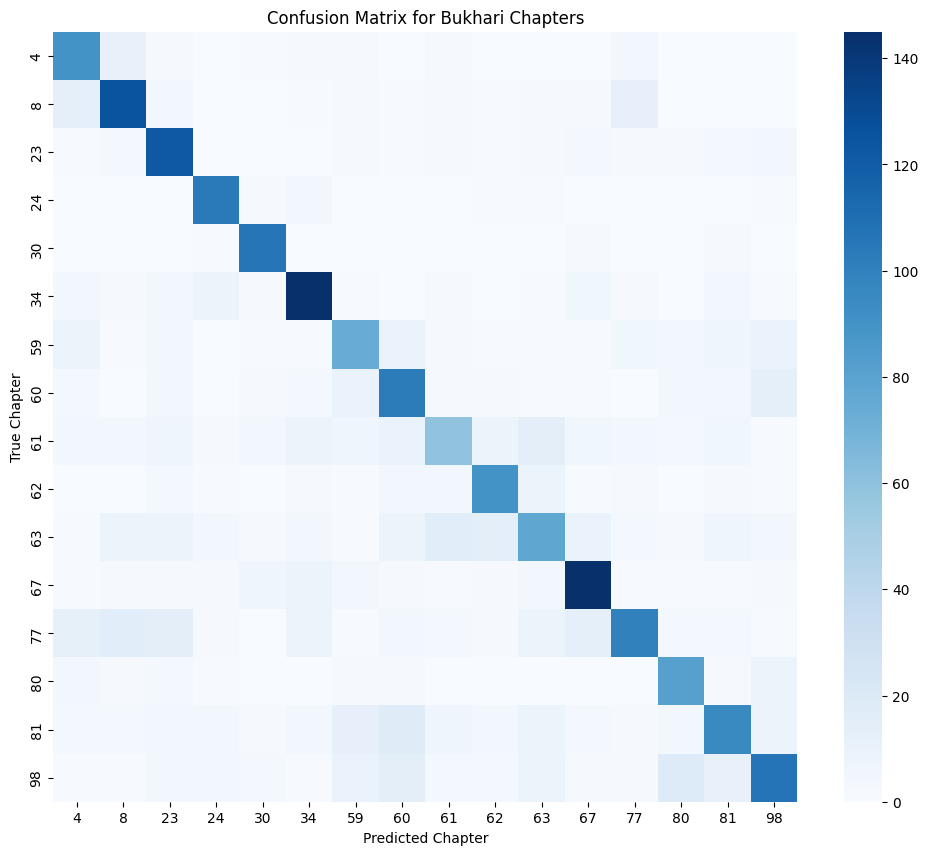

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Compute the confusion matrix to visualize KNN classification performance
cm = confusion_matrix(y, y_pred, labels=sorted(df_subset["chapter_no"].unique()))

# Plot confusion matrix as a heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    annot=False,                           # No text annotations inside the cells
    cmap="Blues",                          # Color theme
    xticklabels=sorted(df_subset["chapter_no"].unique()),  # Predicted labels
    yticklabels=sorted(df_subset["chapter_no"].unique())   # True labels
)

plt.xlabel("Predicted Chapter")
plt.ylabel("True Chapter")
plt.title("Confusion Matrix for Bukhari Chapters")
plt.show()

# TOP K

In [ ]:
# Compute Top-k retrieval accuracy for different values of k
top1  = top_k_accuracy(sim_matrix, chapter_ids, k=1)
top3  = top_k_accuracy(sim_matrix, chapter_ids, k=3)
top5  = top_k_accuracy(sim_matrix, chapter_ids, k=5)
top10 = top_k_accuracy(sim_matrix, chapter_ids, k=10)
top15 = top_k_accuracy(sim_matrix, chapter_ids, k=15)

# Display formatted results
print(f"Top-1 Accuracy:  {top1:.4f}")
print(f"Top-3 Accuracy:  {top3:.4f}")
print(f"Top-5 Accuracy:  {top5:.4f}")
print(f"Top-10 Accuracy: {top10:.4f}")
print(f"Top-15 Accuracy: {top15:.4f}")


Top-1 Accuracy:  0.5113
Top-3 Accuracy:  0.7098
Top-5 Accuracy:  0.7723
Top-10 Accuracy: 0.8485
Top-15 Accuracy: 0.8827


In [14]:
# Precision & Recall with matching K values
P1,  R1  = precision_recall_at_k(sim_matrix, chapter_ids, k=1)
P3,  R3  = precision_recall_at_k(sim_matrix, chapter_ids, k=3)
P5,  R5  = precision_recall_at_k(sim_matrix, chapter_ids, k=5)
P10, R10 = precision_recall_at_k(sim_matrix, chapter_ids, k=10)
P15, R15 = precision_recall_at_k(sim_matrix, chapter_ids, k=15)

print("Precision-1  =", P1)
print("Recall-1     =", R1)
print("Precision-3  =", P3)
print("Recall-3     =", R3)
print("Precision-5  =", P5)
print("Recall-5     =", R5)
print("Precision-10 =", P10)
print("Recall-10    =", R10)
print("Precision-15 =", P15)
print("Recall-15    =", R15)


Precision-1  = 0.5113215314944421
Recall-1     = 0.00349259380839588
Precision-3  = 0.4897763139838067
Recall-3     = 0.010098658141060616
Precision-5  = 0.47533964594483324
Recall-5     = 0.01641653754881359
Precision-10 = 0.4669411280362289
Recall-10    = 0.03232025365680243
Precision-15 = 0.4587896253602306
Recall-15    = 0.04771700317447853


# retrieval

In [ ]:
import torch
from sentence_transformers.util import cos_sim

def get_top_k_similar_hadiths_bert(query_text, model, embeddings, df_bukhari, k=5):
    # Encode the query Hadith into an embedding vector
    query_emb = model.encode([query_text], convert_to_tensor=True)

    # Move query embedding to CPU for computation
    query_emb = query_emb.cpu()

    # Convert stored embeddings to a CPU tensor
    hadith_emb = torch.tensor(embeddings).cpu()

    # Compute cosine similarity between query embedding and all Hadith embeddings
    similarities = cos_sim(query_emb, hadith_emb)[0]  # shape: (N,)

    # Retrieve top-k most similar Hadiths
    top_k_scores, top_k_indices = torch.topk(similarities, k=k)

    results = []
    for score, idx in zip(top_k_scores, top_k_indices):
        idx = int(idx)

        # Collect similarity score, chapter number, and Hadith text
        results.append({
            "similarity": float(score),
            "chapter_no": int(df_bukhari.loc[idx, "chapter_no"]),
            "text": df_bukhari.loc[idx, "clean_text"]
        })

    return results


In [ ]:
# Define the query Hadith for which we want to retrieve similar narrations
query = "لقِّنوا موتاكم لا إلهَ إلَّا اللهُ؛ فإنَّه مَن كان آخرُ كلمتِه لا إلهَ إلَّا اللهُ عندَ الموتِ، دخَل الجنَّةَ يومًا مِن الدَّهرِ، وإنْ أصابه قبْلَ ذلك ما أصابه"

# Retrieve the Top-5 most semantically similar Hadiths using the fine-tuned model
results = get_top_k_similar_hadiths_bert(
    query_text=query,
    model=model,              # Fine-tuned AraBERT-SimCSE model
    embeddings=embeddings,    # Precomputed Hadith embeddings
    df_bukhari=df_bukhari,    # Metadata + clean text
    k=5                       # Number of retrieved results
)

# Display results with similarity score, chapter number, and original Hadith text
for r in results:
    print("Similarity:", r["similarity"])
    print("Chapter:", r["chapter_no"])
    print("Text:", r["text"])
    print("-"*60)

Similarity: 0.9630205631256104
Chapter: 63
Text: حدثنا عبد الله بن يوسف، قال سمعت مالكا، يحدث عن أبي النضر، مولى عمر بن عبيد الله عن عامر بن سعد بن أبي وقاص، عن أبيه، قال ما سمعت النبي صلى الله عليه وسلم يقول لأحد يمشي على الأرض إنه من أهل الجنة‏.‏ إلا لعبد الله بن سلام قال وفيه نزلت هذه الآية ‏{‏وشهد شاهد من بني إسرائيل‏}‏ الآية‏.‏ قال لا أدري قال مالك الآية أو في الحديث‏.‏
------------------------------------------------------------
Similarity: 0.9596692323684692
Chapter: 60
Text: ‏ من اعتجن بمائه ‏
------------------------------------------------------------
Similarity: 0.9595065116882324
Chapter: 23
Text: حدثنا محمد بن بشار، حدثنا غندر، حدثنا شعبة، عن سعد، عن طلحة، قال صليت خلف ابن عباس  رضى الله عنهما ‏.‏ حدثنا محمد بن كثير، أخبرنا سفيان، عن سعد بن إبراهيم، عن طلحة بن عبد الله بن عوف، قال صليت خلف ابن عباس  رضى الله عنهما  على جنازة فقرأ بفاتحة الكتاب قال ليعلموا أنها سنة‏.‏
------------------------------------------------------------
Similarity: 0.9558016657829285
Chapter: 81
Tex

In [ ]:
# Define a second query Hadith to test semantic retrieval on a different topic
query = "من احتكر فهو خاطئ. فقيل لسعيد: فإنك تحتكر، قال سعيد: إن معمرا الذي كان يحدث هذا الحديث، كان يحتكر."

# Retrieve the Top-5 most similar Hadiths from Sahih Bukhari using cosine similarity
results = get_top_k_similar_hadiths_bert(
    query_text=query,
    model=model,              # Fine-tuned AraBERT-SimCSE model
    embeddings=embeddings,    # Precomputed embeddings for all selected chapters
    df_bukhari=df_bukhari,    # Contains text + chapter metadata
    k=5                       # Number of similar Hadiths to retrieve
)

# Display the retrieved Hadiths with similarity scores and chapter numbers
for r in results:
    print("Similarity:", r["similarity"])
    print("Chapter:", r["chapter_no"])
    print("Text:", r["text"])
    print("-"*60)


Similarity: 0.9638127684593201
Chapter: 34
Text: ‏ خذيها واشترطي لهم الولاء، فإنما الولاء لمن أعتق ‏ ‏ أما بعد ما بال رجال يشترطون شروطا ليست في كتاب الله، ما كان من شرط ليس في كتاب الله فهو باطل وإن كان مائة شرط، قضاء الله أحق، وشرط الله أوثق، وإنما الولاء لمن أعتق ‏
------------------------------------------------------------
Similarity: 0.963295042514801
Chapter: 98
Text: ‏ إذا تقرب العبد مني شبرا تقربت منه ذراعا وإذا تقرب مني ذراعا تقربت منه باعا أو بوعا ‏
------------------------------------------------------------
Similarity: 0.9583258628845215
Chapter: 34
Text: ‏ الذهب بالذهب مثلا بمثل والورق بالورق مثلا بمثل ‏
------------------------------------------------------------
Similarity: 0.9583142995834351
Chapter: 81
Text: ‏ هذا المال  وربما قال سفيان قال لي يا حكيم  إن هذا المال خضرة حلوة، فمن أخذه بطيب نفس بورك له فيه، ومن أخذه بإشراف نفس لم يبارك له فيه، وكان كالذي يأكل ولا يشبع، واليد العليا خير من اليد السفلى ‏
------------------------------------------------------------
Simila

# save

In [ ]:
import numpy as np
import shutil

# Create a ZIP archive of the fine-tuned model folder for export or download
shutil.make_archive("my_arabert_simcse_model", 'zip', "my_arabert_simcse_model")

'/kaggle/working/my_arabert_simcse_model.zip'

# DOC2VEC Base model

In [ ]:
# Extract all cleaned Matn texts from the filtered Bukhari dataset
texts = df_bukhari["clean_text"].tolist()

# Display total number of Hadith texts available for embedding or evaluation
print("عدد النصوص:", len(texts))

عدد النصوص: 2429


In [ ]:
from gensim.models.doc2vec import TaggedDocument
from gensim.utils import simple_preprocess

# Convert each Hadith text into a TaggedDocument:
# - simple_preprocess() tokenizes and normalizes the text
# - each document is tagged with a unique ID required by Doc2Vec
documents = [
    TaggedDocument(simple_preprocess(t), [i])
    for i, t in enumerate(texts)
]

# Print total number of documents prepared for Doc2Vec training
print("عدد الوثائق:", len(documents))

عدد الوثائق: 2429


In [ ]:
from gensim.models import Doc2Vec

# Initialize a Doc2Vec model with basic hyperparameters:
model = Doc2Vec(
    vector_size=100,   # Dimensionality of the learned document embeddings
    min_count=1,       # Include all words (no minimum frequency threshold)
    epochs=10          # Number of training iterations over the corpus
)

In [ ]:
# Build the vocabulary from the prepared TaggedDocument corpus
model.build_vocab(documents)

# Train the Doc2Vec model on the full corpus
model.train(
    documents,
    total_examples=model.corpus_count,  # Number of documents
    epochs=model.epochs                 # Training epochs specified earlier
)

# Confirmation message
print("Doc2Vec baseline DONE")

Doc2Vec baseline DONE 


In [ ]:
# Generate document embeddings by inferring a vector for each Hadith text
embeddings = [
    model.infer_vector(simple_preprocess(t))
    for t in texts
]

# Print total number of generated embeddings
print(":", len(embeddings))

# Preview the first 10 dimensions of the first embedding vector
print("EMM:", embeddings[0][:10])

: 2429
EMM: [-0.0135442   0.01373114  0.00904488 -0.00601326  0.01264407 -0.03041835
  0.01217005  0.04982082 -0.01143679 -0.01369863]


In [ ]:
import numpy as np

# Convert list of inferred Doc2Vec embeddings into a 2D NumPy array
X = np.array(embeddings)

# Extract chapter labels corresponding to each Hadith (for evaluation/classification)
y = df_bukhari["chapter_no"].values

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import numpy as np

# Convert inferred Doc2Vec embeddings to a NumPy array (feature matrix)
X = np.array(embeddings)

# Chapter labels used as ground truth for evaluation
y = df_bukhari["chapter_no"].values

# Initialize a KNN classifier using cosine distance (more appropriate for embeddings)
knn = KNeighborsClassifier(n_neighbors=5, metric="cosine")

# Train KNN on the Doc2Vec embedding space
knn.fit(X, y)

# Predict chapter labels for all embeddings
y_pred = knn.predict(X)

# Compute KNN accuracy as baseline performance for Doc2Vec
knn_acc = accuracy_score(y, y_pred)

print("KNN Accuracy (Doc2Vec baseline):", round(knn_acc, 3))
ة

KNN Accuracy (Doc2Vec baseline): 0.366


In [ ]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# Compute the full cosine similarity matrix between all Doc2Vec embeddings (shape: N x N)
sim_matrix = cosine_similarity(embeddings)


In [ ]:
# Extract chapter labels as a NumPy array to use during retrieval evaluation
chapter_ids = df_bukhari["chapter_no"].values


In [ ]:
def top_k_accuracy(sim_matrix, chapter_ids, k):
    N = len(chapter_ids)   # Total number of Hadiths being evaluated
    correct = 0

    for i in range(N):
        sims = sim_matrix[i]              # Similarity scores for query Hadith i
        sorted_idx = np.argsort(sims)[::-1]  # Indices sorted from highest to lowest similarity

        # Exclude the query itself, then take top-k most similar Hadiths
        top_k_idx = [j for j in sorted_idx if j != i][:k]

        # Retrieve the chapters of the selected top-k candidates
        predicted_chapters = chapter_ids[top_k_idx]

        # Count as correct if any of the top-k Hadiths is from the same chapter
        if chapter_ids[i] in predicted_chapters:
            correct += 1

    # Return the proportion of correctly re


In [ ]:
import numpy as np

def precision_recall_at_k(sim_matrix, chapter_ids, k):
    N = len(chapter_ids)      # Number of Hadiths in the evaluation set
    precision_sum = 0
    recall_sum = 0

    for i in range(N):
        sims = sim_matrix[i]  # Similarity scores for Hadith i

        # Sort indices by descending similarity
        sorted_idx = np.argsort(sims)[::-1]

        # Select top-k most similar Hadiths, excluding the Hadith itself
        top_k_idx = [j for j in sorted_idx if j != i][:k]

        # Chapter labels of retrieved candidates
        predicted_chapters = chapter_ids[top_k_idx]

        # True chapter label of query Hadith
        true_label = chapter_ids[i]

        # Number of retrieved items that belong to the same chapter
        hits = np.sum(predicted_chapters == true_label)

        # Precision@k = correct retrieved / k
        precision_sum += hits / k

        # Total number of Hadiths that share this chapter (relevant items)
        total_relevant = np.sum(chapter_ids == true_label)

        # Recall@k = correct retrieved / total relevant
        recall_sum += hits / total_relevant

    # Return macro-averaged precision and recall
    return precision_sum / N, recall_sum / N

In [ ]:
# Compute Top-k retrieval accuracy for multiple values of k
top1  = top_k_accuracy(sim_matrix, chapter_ids, k=1)
top3  = top_k_accuracy(sim_matrix, chapter_ids, k=3)
top5  = top_k_accuracy(sim_matrix, chapter_ids, k=5)
top10 = top_k_accuracy(sim_matrix, chapter_ids, k=10)
top15 = top_k_accuracy(sim_matrix, chapter_ids, k=15)

# Print Top-k performance with 4-decimal formatting
print(f"Top-1 Accuracy:  {top1:.4f}")
print(f"Top-3 Accuracy:  {top3:.4f}")
print(f"Top-5 Accuracy:  {top5:.4f}")
print(f"Top-10 Accuracy: {top10:.4f}")
print(f"Top-15 Accuracy: {top15:.4f}")


Top-1 Accuracy:  0.1075
Top-3 Accuracy:  0.2573
Top-5 Accuracy:  0.3713
Top-10 Accuracy: 0.5620
Top-15 Accuracy: 0.6793


In [ ]:
# Compute Precision@k and Recall@k for different values of k
P1,  R1  = precision_recall_at_k(sim_matrix, chapter_ids, k=1)
P3,  R3  = precision_recall_at_k(sim_matrix, chapter_ids, k=3)
P5,  R5  = precision_recall_at_k(sim_matrix, chapter_ids, k=5)
P10, R10 = precision_recall_at_k(sim_matrix, chapter_ids, k=10)
P15, R15 = precision_recall_at_k(sim_matrix, chapter_ids, k=15)

# Display precision values only (as in baseline evaluation)
print("Precision-1  =", P1)
print("Precision-3  =", P3)
print("Precision-5  =", P5)
print("Precision-10 =", P10)
print("Precision-15 =", P15)

Precision-1  = 0.11939069575957184
Precision-3  = 0.10978454782489402
Precision-5  = 0.10201729106628174
Precision-10 = 0.09481268011527257
Precision-15 = 0.09103883628379245


# retrieval

In [ ]:
from gensim.utils import simple_preprocess
import numpy as np
import torch
from sentence_transformers.util import cos_sim

def get_top_k_similar_hadiths_doc2vec(query_text, model, embeddings, df_bukhari, k=5):
    
    # Preprocess the query Hadith: tokenize & normalize
    tokens = simple_preprocess(query_text)

    # Infer a Doc2Vec embedding for the query (NumPy vector)
    query_emb = model.infer_vector(tokens)

    # Convert query embedding to a PyTorch tensor of shape (1, d)
    query_emb = torch.tensor(query_emb).unsqueeze(0).float()

    # Convert all stored Doc2Vec embeddings to a PyTorch tensor
    hadith_emb = torch.tensor(embeddings).float()

    # Compute cosine similarity between query embedding and all document embeddings
    similarities = cos_sim(query_emb, hadith_emb)[0]  # Output shape: (N,)

    # Retrieve the top-k most similar Hadiths
    top_k_scores, top_k_indices = torch.topk(similarities, k=k)

    results = []
    for score, idx in zip(top_k_scores, top_k_indices):
        idx = int(idx)

        # Collect similarity score, chapter number, and text of retrieved Hadith
        results.append({
            "similarity": float(score),
            "chapter_no": int(df_bukhari.loc[idx, "chapter_no"]),
            "text": df_bukhari.loc[idx, "clean_text"]
        })

    return results


In [ ]:
# Query Hadith to test retrieval performance using the Doc2Vec baseline
query = "لقِّنوا موتاكم لا إلهَ إلَّا اللهُ؛ فإنَّه مَن كان آخرُ كلمتِه لا إلهَ إلَّا اللهُ عندَ الموتِ، دخَل الجنَّةَ يومًا مِن الدَّهرِ، وإنْ أصابه قبْلَ ذلك ما أصابه"

# Retrieve Top-5 semantically similar Hadiths from the Doc2Vec embedding space
results = get_top_k_similar_hadiths_doc2vec(
    query_text=query,
    model=model,          # Doc2Vec model
    embeddings=embeddings,
    df_bukhari=df_bukhari,
    k=5
)

# Display similarity score, chapter number, and text for each retrieved Hadith
for r in results:
    print("Similarity:", r["similarity"])
    print("Chapter:", r["chapter_no"])
    print("Text:", r["text"])
    print("-"*60)


Similarity: 0.9588814973831177
Chapter: 59
Text: ‏ إذا مات أحدكم فإنه يعرض عليه مقعده بالغداة والعشي، فإن كان من أهل الجنة فمن أهل الجنة، وإن كان من أهل النار فمن أهل النار ‏
------------------------------------------------------------
Similarity: 0.9548697471618652
Chapter: 77
Text: ‏ إن أشد الناس عذابا عند الله يوم القيامة المصورون ‏
------------------------------------------------------------
Similarity: 0.9545716047286987
Chapter: 77
Text: ‏ من جر ثوبه مخيلة، لم ينظر الله إليه يوم القيامة ‏ ‏ من جر ثوبه ‏
------------------------------------------------------------
Similarity: 0.9522133469581604
Chapter: 24
Text: ‏ ليس على المسلم صدقة في عبده ولا في فرسه ‏
------------------------------------------------------------
Similarity: 0.9428418874740601
Chapter: 67
Text: ‏ لا يجمع بين المرأة وعمتها، ولا بين المرأة وخالتها ‏
------------------------------------------------------------


In [ ]:
# Second query Hadith used to evaluate Doc2Vec retrieval performance
query = "من احتكر فهو خاطئ. فقيل لسعيد: فإنك تحتكر، قال سعيد: إن معمرا الذي كان يحدث هذا الحديث، كان يحتكر."

# Retrieve Top-5 most similar Hadiths based on Doc2Vec embeddings
results = get_top_k_similar_hadiths_doc2vec(
    query_text=query,
    model=model,          # Doc2Vec model
    embeddings=embeddings,
    df_bukhari=df_bukhari,
    k=5
)

# Print similarity scores, chapter numbers, and retrieved texts
for r in results:
    print("Similarity:", r["similarity"])
    print("Chapter:", r["chapter_no"])
    print("Text:", r["text"])
    print("-"*60)

Similarity: 0.9309897422790527
Chapter: 63
Text: حدثنا علي بن عبد الله، حدثنا سفيان، قال كان عمرو يقول حدثنا سعيد بن المسيب، عن أبيه، عن جده، قال جاء سيل في الجاهلية فكسا ما بين الجبلين‏.‏ قال سفيان ويقول إن هذا لحديث له شأن‏.‏
------------------------------------------------------------
Similarity: 0.9286319613456726
Chapter: 63
Text: حدثنا عمر بن حفص، حدثنا أبي، حدثنا الأعمش، حدثنا إبراهيم، عن أبي معمر، عن عبد الله  رضى الله عنه  قال انشق القمر‏.‏
------------------------------------------------------------
Similarity: 0.9156291484832764
Chapter: 98
Text: ‏ لا ينبغي لعبد أن يقول إنه خير من يونس بن متى ‏
------------------------------------------------------------
Similarity: 0.914331316947937
Chapter: 60
Text: ‏ لا ينبغي لعبد أن يقول أنا خير من يونس بن متى ‏
------------------------------------------------------------
Similarity: 0.9134037494659424
Chapter: 77
Text: وقال لي مسدد حدثنا معتمر، سمعت أبي قال، رأيت على أنس برنسا أصفر من خز‏.‏
----------------------------------------------